# Recommendation Systems: Neural and Sequential Recommenders

> **Who is this for:** you know collaborative filtering and matrix factorisation from [`01_recommendation_systems`](01_recommendation_systems.ipynb) and want to build the models used in modern production recommenders: implicit-feedback matrix factorisation, two-tower retrieval, and sequence models (GRU4Rec, SASRec), evaluated the way industry and recent research do it. It is also preparation for ML-engineer interviews, where "design a recommender" is a classic question.
>
> **What you will learn:**
> - A sound **evaluation protocol**: leave-last-out split, **Recall@k, NDCG@k, MRR**, why **sampled metrics** mislead, and popularity bias
> - **BPR** matrix factorisation for implicit feedback, in PyTorch
> - A **two-tower retrieval model** with in-batch negatives, temperature and logQ correction, plus approximate nearest-neighbour retrieval (an IVF index from scratch vs exact `NearestNeighbors`)
> - **Sequential recommendation**: a Markov-chain baseline → a **GRU4Rec**-style GRU → a small **SASRec**-style self-attention model
> - A **retrieval → ranking → re-ranking** pipeline, with **MMR diversity** and **calibration**
> - **Cold start** with content features (a hybrid tower)
> - Offline evaluation of a new policy from logged bandit feedback with **inverse propensity scoring (IPS)**
> - A **latency and size budget** for production
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [PyTorch from zero](../../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb); [`01_recommendation_systems`](01_recommendation_systems.ipynb); [RNNs](../../05_Deep_Learning/04_rnn_lstm_gru.ipynb) and [transformers](../../05_Deep_Learning/05_transformers_architecture.ipynb) for Section 4.
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. All data is synthetic, with a *planted* structure, so we know what a good model should find. The whole notebook runs in about 1–2 minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Rendle et al. (2009, BPR), Hidasi et al. (2016, GRU4Rec), Kang & McAuley (2018, SASRec), Yi et al. (2019, sampling-bias-corrected two-tower) and Krichene & Rendle (2020, sampled metrics).

## Explained simply

A **recommender** guesses what you will want next: the next video, song, product or news story. Old-style recommenders looked at your whole history as one bag ("people who bought X also bought Y"). Modern ones also look at the **order**: if you just watched episode 3 of a series, episode 4 is a very good guess, even if you usually watch comedies. A good bookshop assistant does both: they remember your taste and notice what you picked up a minute ago.

Big apps have millions of items, so they work in **stages**, like a job hiring process: a fast first round picks a few hundred candidates from millions (the "CV screen"), a slower, smarter model ranks those candidates (the "interview"), and a final step adjusts the list so it is varied and fair (the "final panel").

**Tiny example.** You watched *Space Saga 1*, *Space Saga 2*, then a cooking show. Candidates: *Space Saga 3*, *Cooking Show 2*, a random popular film. A "taste only" model might say "you like space and cooking, both are fine". A sequence model notices the last thing was a cooking show and that you finish series, and ranks *Cooking Show 2* and *Space Saga 3* at the top, with the popular film last.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Two-tower retrieval | turn users and items into points in the same space and fetch the nearest items | YouTube, Pinterest and app-store candidate generation |
| Sequential recommender | predict the next item from the order of recent items | "up next" on streaming sites, session-based shopping |
| Offline evaluation (IPS) | estimate how a new recommender would do, using logs of the old one | A/B-test planning at e-commerce and ad companies |

### How this notebook is different from its neighbours
- [`01_recommendation_systems`](01_recommendation_systems.ipynb) covers user/item CF, explicit-rating matrix factorisation and a quick tour of neural models. Here we work with **implicit feedback and sequences**, implement the models in PyTorch, and focus on **evaluation**.
- [`02_industry_product_recommender`](02_industry_product_recommender.ipynb) builds an applied product recommender; this notebook gives the modelling depth behind such systems.
- [`01_supervised/12_learning_to_rank`](../01_supervised/12_learning_to_rank.ipynb) covers ranking losses and metrics in general; we reuse NDCG here.
- [`11_Reinforcement_Learning/07_multi_armed_bandits`](../../11_Reinforcement_Learning/07_multi_armed_bandits.ipynb) covers exploration; Section 7 uses bandit-style logs for off-policy evaluation.

## Table of contents
1. The data and the evaluation protocol
2. BPR matrix factorisation
3. Two-tower retrieval and approximate nearest neighbours
4. Sequential recommenders: Markov chain, GRU4Rec, SASRec
5. Retrieval → ranking → re-ranking (diversity and calibration)
6. Cold start with content features
7. Offline vs online evaluation: inverse propensity scoring
8. A latency and size budget for production
9. How this connects to modern AI
10. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")     # be polite on shared machines
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import sys, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
pd.set_option("display.precision", 4)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import HistGradientBoostingClassifier
torch.set_num_threads(2)
torch.manual_seed(0)
rng = np.random.default_rng(0)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. The data and the evaluation protocol

> 💬 **In plain English:** build a fake streaming service whose users follow known habits, then score models fairly on what each user watched last.

### 1.1 A synthetic catalogue with planted structure
We simulate a streaming service with **300 items in 10 genres**; within each genre the 30 items form a **series** (episode 0, 1, 2, …). Each item has a hidden **quality**, and earlier episodes and better items are more popular. Each of **1000 users** has a hidden taste over genres (most users like 1–3 genres). Users watch 15–40 items, never the same one twice. After each item the next one is chosen as:

| Probability | What the user does | Which model can learn it |
|---|---|---|
| 0.35 | watches the **next episode** of the series they just watched (if not seen yet) | any sequence model, even a first-order Markov chain |
| 0.20 | **interleaves**: continues the series they watched **two items ago** (watching two shows in parallel) | only sequence models that look further back than one step (GRU, SASRec) |
| 0.30 | picks a new item from **one of their favourite genres**, popular items more likely | user-taste models (MF, two-tower) and sequence models with long memory |
| 0.15 | picks a **globally popular** item | popularity |

(When the rule's item was already watched, the user falls back to the taste rule.)

Because we wrote the simulator, we know the "true" taste of every user, which we use for cold-start evaluation and for the bandit simulation later.

In [2]:
G, PER_G = 10, 30
n_items, n_users = G * PER_G, 1000
item_genre = np.repeat(np.arange(G), PER_G)               # genre of each item
item_pos = np.tile(np.arange(PER_G), G)                   # episode number within its series
quality = rng.normal(0, 1, n_items)                       # hidden item quality
pop_w = np.exp(0.8 * quality) / np.sqrt(1 + item_pos)     # better items and early episodes are more popular
pop_p = pop_w / pop_w.sum()
theta = rng.dirichlet(np.full(G, 0.3), size=n_users)      # each user's hidden taste over genres

def next_item(u, last, seen, prev2=None):
    r = rng.random()
    if last is not None and r < 0.35 and item_pos[last] < PER_G - 1 and (last + 1) not in seen:
        return last + 1                                    # continue the series just watched
    if prev2 is not None and 0.35 <= r < 0.55 and item_pos[prev2] < PER_G - 1 and (prev2 + 1) not in seen:
        return prev2 + 1                                   # interleave: continue the series from two items ago
    if last is None or r < 0.85:
        g = rng.choice(G, p=theta[u])                      # a favourite genre
        cand = np.flatnonzero(item_genre == g)
    else:
        cand = np.arange(n_items)                          # anything popular
    cand = cand[~np.isin(cand, list(seen))]
    if len(cand) == 0:
        cand = np.setdiff1d(np.arange(n_items), list(seen))
    p = pop_p[cand] / pop_p[cand].sum()
    return int(rng.choice(cand, p=p))

seqs = []
for u in range(n_users):
    seq, seen, last = [], set(), None
    for _ in range(rng.integers(15, 41)):
        nxt = next_item(u, last, seen, seq[-2] if len(seq) >= 2 else None)
        seq.append(nxt); seen.add(nxt); last = nxt
    seqs.append(seq)

# Leave-last-out split: last item = test target, second-to-last = validation target, the rest = training
train_seqs = [s[:-2] for s in seqs]
val_target = np.array([s[-2] for s in seqs]); test_target = np.array([s[-1] for s in seqs])
n_train = sum(map(len, train_seqs))
print(f"{n_users} users, {n_items} items, {sum(map(len, seqs))} interactions ({n_train} for training)")
print("user 0 watched:", seqs[0][:12], "...")
print("as (genre, episode):", [(int(item_genre[i]), int(item_pos[i])) for i in seqs[0][:8]], "...")

1000 users, 300 items, 27299 interactions (25299 for training)
user 0 watched: [19, 157, 158, 159, 160, 161, 162, 163, 271, 16, 0, 1] ...
as (genre, episode): [(0, 19), (5, 7), (5, 8), (5, 9), (5, 10), (5, 11), (5, 12), (5, 13)] ...


### 1.2 Metrics
We use the **leave-last-out** protocol: for every user, the model sees the history and must rank the held-out next item among all items the user has not seen yet. With a single relevant item at rank r (1 = top):

| Metric | Formula (one target) | Meaning |
|---|---|---|
| **Recall@k** (= HitRate@k here) | 1 if r ≤ k else 0 | did the right item make the top k? |
| **NDCG@k** | 1 / log₂(r + 1) if r ≤ k else 0 | like Recall@k but rewards being higher in the list |
| **MRR** | 1 / r | average reciprocal rank over the whole list |

**Sampled metrics.** Many papers rank the target against only **100 random negatives** instead of the full catalogue to save time. Krichene & Rendle (2020) showed that sampled metrics are **inflated** and can even **reverse** the order of models. We compute both to see it.

**Worked example.** If the target is ranked 3rd: Recall@10 = 1, NDCG@10 = 1/log₂4 = 0.5, MRR = 1/3. If it is ranked 25th: Recall@10 = 0, NDCG@10 = 0, MRR = 0.04.

In [3]:
r_eval = np.random.default_rng(123)
def history(u, split):
    return train_seqs[u] if split == "val" else train_seqs[u] + [int(val_target[u])]
def target(split):
    return val_target if split == "val" else test_target
# Fixed sampled negatives (shared by every model, so the comparison is fair)
SAMPLED = {}
for split in ("val", "test"):
    negs = []
    for u in range(n_users):
        pool = np.setdiff1d(np.arange(n_items), history(u, split) + [int(target(split)[u])])
        negs.append(r_eval.choice(pool, 100, replace=False))
    SAMPLED[split] = np.array(negs)

def evaluate(S, split="test", k=10):
    """S: (n_users, n_items) scores. Seen items are excluded. Ties are counted as half."""
    S = S.astype(float).copy()
    y = target(split)
    for u in range(n_users):
        S[u, history(u, split)] = -np.inf
    st = S[np.arange(n_users), y][:, None]
    rank = 1 + (S > st).sum(1) + 0.5 * ((S == st).sum(1) - 1)            # full-catalogue rank
    Sn = np.take_along_axis(S, SAMPLED[split], axis=1)
    rank_s = 1 + (Sn > st).sum(1) + 0.5 * (Sn == st).sum(1)              # rank among 100 negatives
    ndcg = lambda r: np.where(r <= k, 1 / np.log2(r + 1), 0).mean()
    return {"Recall@10": (rank <= k).mean(), "NDCG@10": ndcg(rank), "MRR": (1 / rank).mean(),
            "sampled Recall@10": (rank_s <= k).mean(), "sampled NDCG@10": ndcg(rank_s)}

# Baseline 1: random scores. Baseline 2: popularity counted on the training data
pop_count = np.bincount(np.concatenate(train_seqs), minlength=n_items).astype(float)
results = {}
results["random"] = evaluate(np.random.default_rng(1).random((n_users, n_items)))
results["popularity"] = evaluate(np.tile(pop_count, (n_users, 1)))
pd.DataFrame(results).T.round(3)

,Recall@10,NDCG@10,MRR,sampled Recall@10,sampled NDCG@10
random,0.038,0.017,0.023,0.090,0.041
popularity,0.092,0.046,0.048,0.199,0.098


In [4]:
def popularity_bias(S, k=10, split="test"):
    """Catalogue coverage and average popularity percentile of the top-k lists."""
    S = S.astype(float).copy()
    for u in range(n_users):
        S[u, history(u, split)] = -np.inf
    top = np.argsort(-S, axis=1)[:, :k]
    pct = pd.Series(pop_count).rank(pct=True).values
    return {"coverage": len(np.unique(top)) / n_items, "avg popularity percentile": pct[top].mean()}

print("popularity model:", {k: round(v, 3) for k, v in popularity_bias(np.tile(pop_count, (n_users, 1))).items()})
print("test targets themselves: avg popularity percentile =",
      round(pd.Series(pop_count).rank(pct=True).values[test_target].mean(), 3))

popularity model: {'coverage': 0.077, 'avg popularity percentile': np.float64(0.977)}
test targets themselves: avg popularity percentile = 0.609


**What just happened?** Random scores give Recall@10 ≈ 10/270 (a few per cent), and popularity does much better. Notice the **sampled** columns: with only 100 negatives, even random guessing gets about 10/101 ≈ 0.1, and popularity's scores roughly double. Sampled metrics make every model look better than it is.

The popularity model recommends a tiny slice of the catalogue (low **coverage**) and only head items, while users' actual next items are noticeably less popular on average. That gap is **popularity bias**: a model that only learns popularity looks acceptable offline but starves the long tail.

> ⚠️ **Common mistake:** a random train/test split of interactions for sequential data. It leaks the future into training (the model sees episode 5 when predicting episode 4). Split by time: leave-last-out per user, or a global time cut-off.

## 2. BPR matrix factorisation for implicit feedback

> 💬 **In plain English:** learn a taste vector per user and per item so that watched items score higher than random ones.

**Implicit feedback** (views, clicks, purchases) has only positives; a missing interaction may mean "not interested" or "never saw it". **Bayesian Personalised Ranking** (Rendle et al., 2009) does not try to predict a rating; it learns that a user prefers an item they interacted with (i) over a random item they did not (j):

$$\mathcal L_{\text{BPR}} = -\sum_{(u,i,j)} \log \sigma\big(\hat x_{ui} - \hat x_{uj}\big) + \lambda\lVert\Theta\rVert^2, \qquad \hat x_{ui} = \mathbf p_u^\top \mathbf q_i + b_i$$

This is a pairwise ranking loss that optimises a smooth version of AUC. Negatives j are sampled uniformly for each positive.

In [5]:
train_pairs = np.array([(u, i) for u, s in enumerate(train_seqs) for i in s])

class MF(nn.Module):
    def __init__(self, n_users, n_items, d=32):
        super().__init__()
        self.P = nn.Embedding(n_users, d); self.Q = nn.Embedding(n_items, d); self.b = nn.Embedding(n_items, 1)
        for e in (self.P, self.Q):
            nn.init.normal_(e.weight, std=0.1)
        nn.init.zeros_(self.b.weight)
    def forward(self, u, i):
        return (self.P(u) * self.Q(i)).sum(-1) + self.b(i).squeeze(-1)
    def all_scores(self):
        return (self.P.weight @ self.Q.weight.T + self.b.weight.T).detach().numpy()

def train_bpr(epochs=15, batch=1024, lr=0.01, wd=1e-4, seed=0):
    torch.manual_seed(seed); r = np.random.default_rng(seed)
    model = MF(n_users, n_items); opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        perm = r.permutation(len(train_pairs)); tot = 0
        for b0 in range(0, len(perm), batch):
            uu, ii = torch.tensor(train_pairs[perm[b0:b0 + batch]].T)
            jj = torch.tensor(r.integers(0, n_items, len(uu)))                  # sampled negatives
            diff = model(uu, ii) - model(uu, jj)
            reg = wd * (model.P(uu).pow(2).sum() + model.Q(ii).pow(2).sum() + model.Q(jj).pow(2).sum()) / len(uu)
            loss = -F.logsigmoid(diff).mean() + reg
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(uu)
        hist.append(tot / len(perm))
    return model, hist

t0 = time.time()
bpr, bpr_hist = train_bpr()
S_bpr = bpr.all_scores()
print(f"BPR trained in {time.time() - t0:.1f}s; loss {bpr_hist[0]:.3f} -> {bpr_hist[-1]:.3f}")
results["BPR-MF"] = evaluate(S_bpr)
pd.DataFrame(results).T.round(3)

BPR trained in 2.9s; loss 0.680 -> 0.208


,Recall@10,NDCG@10,MRR,sampled Recall@10,sampled NDCG@10
random,0.038,0.017,0.023,0.090,0.041
popularity,0.092,0.046,0.048,0.199,0.098
BPR-MF,0.167,0.084,0.079,0.350,0.175


**What just happened?** BPR learns a 32-dimensional vector per user and per item from co-occurrence alone, and beats popularity on every full-catalogue metric because it captures each user's genre taste. It still knows nothing about **order**, so it cannot tell that episode 7 should follow episode 6.

**Complexity.** One epoch costs O(|interactions| · d); scoring all items for one user costs O(n_items · d).

## 3. Two-tower retrieval and approximate nearest neighbours

> 💬 **In plain English:** turn users and items into points in the same space, then quickly fetch the items closest to each user.

**Intuition.** A **two-tower** model has a *user tower* and an *item tower*, each a neural network producing an embedding; the score is their dot product (or cosine). Because the towers are independent, all item embeddings can be **pre-computed and indexed**, and retrieval becomes a nearest-neighbour search: this is how YouTube, Google Play and Pinterest generate candidates from millions of items in milliseconds.

**Training with in-batch negatives.** For a batch of B positive (user, item) pairs, treat the other B − 1 items in the batch as negatives and apply a softmax over the batch:
$$\mathcal L = -\frac1B\sum_{b}\log\frac{\exp(s(u_b, i_b)/\tau)}{\sum_{b'}\exp(s(u_b, i_{b'})/\tau)}$$
- The **temperature τ** sharpens the softmax (small τ focuses on hard negatives).
- Popular items appear as in-batch negatives more often, so they get pushed down too much. The **logQ correction** (Yi et al., 2019) subtracts log(sampling probability of item j) from each logit.

Our item tower is a **hybrid**: an item-ID embedding plus an MLP on **content features** (noisy genre and quality signals, as metadata would be). During training we randomly drop the ID embedding (**ID dropout**) so the content path learns to stand on its own; Section 6 uses it for cold start.

In [6]:
# Content features an item would have at launch: noisy genre one-hot, a noisy quality signal, 4 irrelevant columns
def make_content(genres, qual, r):
    oh = np.eye(G)[genres] + r.normal(0, 0.3, (len(genres), G))
    return np.c_[oh, qual + r.normal(0, 0.5, len(qual)), r.normal(0, 1, (len(genres), 4))].astype(np.float32)
item_feat = make_content(item_genre, quality, np.random.default_rng(5))
n_feat = item_feat.shape[1]

class TwoTower(nn.Module):
    def __init__(self, d=32, id_dropout=0.5):
        super().__init__()
        self.user = nn.Sequential(nn.Embedding(n_users, 64), nn.ReLU(), nn.Linear(64, d))
        self.item_id = nn.Embedding(n_items, d)
        self.item_content = nn.Sequential(nn.Linear(n_feat, 64), nn.ReLU(), nn.Linear(64, d))
        self.id_dropout = id_dropout
        nn.init.normal_(self.item_id.weight, std=0.05)
    def user_vec(self, u):
        return F.normalize(self.user(u), dim=-1)
    def item_vec(self, i, feats, use_id=True):
        v = self.item_content(feats)
        if use_id:
            keep = torch.ones(len(i), 1)
            if self.training:                                   # ID dropout: sometimes rely on content only
                keep = (torch.rand(len(i), 1) > self.id_dropout).float()
            v = v + keep * self.item_id(i)
        return F.normalize(v, dim=-1)

def train_two_tower(epochs=15, batch=512, tau=0.1, logq=True, lr=0.005, seed=0):
    torch.manual_seed(seed); r = np.random.default_rng(seed)
    model = TwoTower(); opt = torch.optim.Adam(model.parameters(), lr=lr)
    feats = torch.tensor(item_feat)
    log_q = torch.tensor(np.log(pop_count / pop_count.sum() + 1e-9), dtype=torch.float32)
    for ep in range(epochs):
        perm = r.permutation(len(train_pairs))
        for b0 in range(0, len(perm), batch):
            uu, ii = torch.tensor(train_pairs[perm[b0:b0 + batch]].T)
            logits = model.user_vec(uu) @ model.item_vec(ii, feats[ii]).T / tau   # (B, B): row b vs every item in batch
            if logq:
                logits = logits - log_q[ii][None, :]            # sampling-bias correction
            loss = F.cross_entropy(logits, torch.arange(len(uu)))
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    return model

t0 = time.time()
tt = train_two_tower()
with torch.no_grad():
    U_tt = tt.user_vec(torch.arange(n_users)).numpy()
    V_tt = tt.item_vec(torch.arange(n_items), torch.tensor(item_feat)).numpy()
S_tt = U_tt @ V_tt.T
print(f"two-tower trained in {time.time() - t0:.1f}s")
results["two-tower"] = evaluate(S_tt)
tt_nologq = train_two_tower(logq=False)
with torch.no_grad():
    S_tt0 = tt_nologq.user_vec(torch.arange(n_users)).numpy() @ tt_nologq.item_vec(torch.arange(n_items), torch.tensor(item_feat)).numpy().T
results["two-tower (no logQ)"] = evaluate(S_tt0)
print("popularity bias, two-tower with logQ:", {k: round(v, 3) for k, v in popularity_bias(S_tt).items()})
print("popularity bias, two-tower without :", {k: round(v, 3) for k, v in popularity_bias(S_tt0).items()})
pd.DataFrame(results).T.round(3)

two-tower trained in 5.8s


popularity bias, two-tower with logQ: {'coverage': 0.993, 'avg popularity percentile': np.float64(0.71)}
popularity bias, two-tower without : {'coverage': 1.0, 'avg popularity percentile': np.float64(0.412)}


,Recall@10,NDCG@10,MRR,sampled Recall@10,sampled NDCG@10
random,0.038,0.017,0.023,0.090,0.041
popularity,0.092,0.046,0.048,0.199,0.098
BPR-MF,0.167,0.084,0.079,0.350,0.175
two-tower,0.191,0.099,0.091,0.382,0.197
two-tower (no logQ),0.154,0.069,0.063,0.315,0.156


**Approximate nearest neighbours (ANN).** With millions of items, even a dot product with every item is too slow per request. An **inverted-file (IVF)** index clusters item embeddings with k-means into `n_lists` buckets; at query time it scores only the items in the `n_probe` buckets whose centroids are closest to the user vector. Below we build one from scratch and compare it with exact search (sklearn's `NearestNeighbors`, which is exact; libraries such as FAISS, ScaNN or HNSW-based vector databases provide the approximate versions at scale; see [`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)).

In [7]:
def build_ivf(V, n_lists=16, n_iter=25, seed=0):
    r = np.random.default_rng(seed)
    C = V[r.choice(len(V), n_lists, replace=False)].copy()
    for _ in range(n_iter):                                   # plain k-means on the item embeddings
        a = (V @ C.T).argmax(1)                               # vectors are unit-length: max dot = nearest
        for j in range(n_lists):
            if (a == j).any():
                C[j] = V[a == j].mean(0)
    a = (V @ C.T).argmax(1)
    return C, [np.flatnonzero(a == j) for j in range(n_lists)]

def ivf_search(q, C, lists, V, k=10, n_probe=2):
    probe = np.argsort(-(C @ q))[:n_probe]                    # closest buckets
    cand = np.concatenate([lists[j] for j in probe])
    return cand[np.argsort(-(V[cand] @ q))[:k]], len(cand)

C_ivf, lists = build_ivf(V_tt)
nn_exact = NearestNeighbors(n_neighbors=10, metric="cosine", algorithm="brute").fit(V_tt)
exact = nn_exact.kneighbors(U_tt, return_distance=False)
assert np.array_equal(np.sort(exact, 1), np.sort(np.argsort(-S_tt, 1)[:, :10], 1))   # cosine NN = top dot products
rows = []
for n_probe in (1, 2, 4, 8, 16):
    rec, scanned = [], []
    for u in range(n_users):
        top, n_scanned = ivf_search(U_tt[u], C_ivf, lists, V_tt, n_probe=n_probe)
        rec.append(len(set(top) & set(exact[u])) / 10); scanned.append(n_scanned)
    rows.append([n_probe, np.mean(scanned) / n_items, np.mean(rec)])
pd.DataFrame(rows, columns=["n_probe (of 16 lists)", "fraction of items scored", "recall@10 vs exact search"]).round(3)

,n_probe (of 16 lists),fraction of items scored,recall@10 vs exact search
0,1,0.084,0.632
1,2,0.156,0.824
2,4,0.295,0.944
3,8,0.568,0.989
4,16,1.000,1.000


**What just happened?**
- The two-tower model is somewhat more accurate than BPR here (it adds content features and a softmax loss over in-batch negatives), but both only learn taste and neither knows order. Its towers are separable, so item vectors can be indexed.
- **logQ correction matters.** Without it, popular items show up as in-batch negatives far more often than unpopular ones and get pushed down too hard: the uncorrected model recommends items with a much *lower* average popularity percentile than users actually watch, and its accuracy drops. Subtracting log Q(j) during training removes this sampling bias, so the scores reflect real preference (including the fact that people do like popular items). Production teams track both accuracy and popularity bias, because either extreme hurts.
- The IVF index finds most of the true top-10 while scoring only a fraction of the catalogue; probing more lists trades speed for recall. With 300 items this is a toy, but with 100 million items it is the difference between 1 ms and 1 s per request.

> 🎓 **Exam / interview tip:** "Why two towers and not one network that takes (user, item) together?" Because two independent towers let you pre-compute item vectors and use ANN search, which is the only way to score millions of items per request. Cross-features (user × item interactions) are then added in the **ranking** stage, where only hundreds of candidates remain.

## 4. Sequential recommenders

> 💬 **In plain English:** read the watch history in order, like reading a sentence, to predict the next item.

**Intuition.** The next item depends strongly on the most recent items (the next episode, an accessory for the phone just bought). Sequential recommenders read the history **in order**.

| Model | Idea | Captures |
|---|---|---|
| **First-order Markov chain** | count transitions i → j in training sequences; score j by P(j \| last item) | short-term order only |
| **GRU4Rec** (Hidasi et al., 2016) | a GRU reads the item sequence; its hidden state predicts the next item (softmax over all items) | order + longer memory |
| **SASRec** (Kang & McAuley, 2018) | causal self-attention (a small decoder-only transformer) over the item sequence | order + which past items matter, in parallel |

All neural models are trained with **next-item prediction** at every position (teacher forcing), exactly like a language model predicts the next token. SASRec ties the output layer to the item embedding matrix, just as many LLMs tie input and output token embeddings.

In [8]:
# Markov chain baseline: transition counts with a little popularity back-off
T_counts = np.zeros((n_items, n_items))
for s in train_seqs:
    for a, b in zip(s[:-1], s[1:]):
        T_counts[a, b] += 1
def markov_scores(split):
    last = np.array([history(u, split)[-1] for u in range(n_users)])
    P = T_counts[last] / np.maximum(T_counts[last].sum(1, keepdims=True), 1)
    return P + 1e-3 * pop_count / pop_count.sum()
S_markov = markov_scores("test")
results["Markov chain"] = evaluate(S_markov)
print({k: round(v, 3) for k, v in results["Markov chain"].items()})

{'Recall@10': np.float64(0.362), 'NDCG@10': np.float64(0.333), 'MRR': np.float64(0.336), 'sampled Recall@10': np.float64(0.446), 'sampled NDCG@10': np.float64(0.374)}


GRU4Rec trained in 14.2s, SASRec in 18.4s


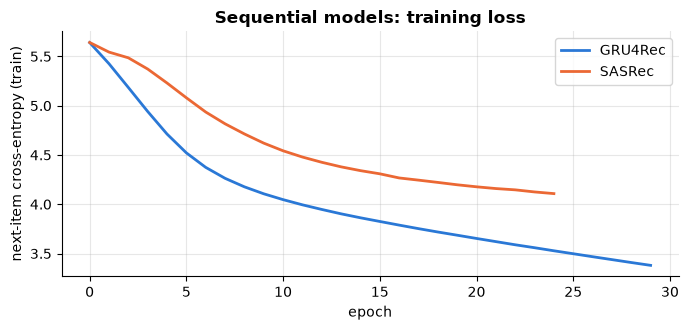

,Recall@10,NDCG@10,MRR,sampled Recall@10,sampled NDCG@10
random,0.038,0.017,0.023,0.090,0.041
popularity,0.092,0.046,0.048,0.199,0.098
BPR-MF,0.167,0.084,0.079,0.350,0.175
two-tower,0.191,0.099,0.091,0.382,0.197
two-tower (no logQ),0.154,0.069,0.063,0.315,0.156
Markov chain,0.362,0.333,0.336,0.446,0.374
GRU4Rec,0.425,0.358,0.348,0.521,0.422
SASRec,0.423,0.352,0.342,0.511,0.411


In [9]:
PAD, MAXLEN = n_items, 40                                   # padding index; sequences are right-padded

def make_training_tensors(seqs_):
    X = np.full((len(seqs_), MAXLEN), PAD); Y = np.full((len(seqs_), MAXLEN), -100)   # -100 = ignored by the loss
    for r_, s in enumerate(seqs_):
        s = s[-(MAXLEN + 1):]
        X[r_, :len(s) - 1] = s[:-1]; Y[r_, :len(s) - 1] = s[1:]                       # predict item t+1 from items <= t
    return torch.tensor(X), torch.tensor(Y)

def make_inference_tensors(split):
    X = np.full((n_users, MAXLEN), PAD); last = np.zeros(n_users, int)
    for u in range(n_users):
        h = history(u, split)[-MAXLEN:]
        X[u, :len(h)] = h; last[u] = len(h) - 1
    return torch.tensor(X), torch.tensor(last)

class GRURec(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.emb = nn.Embedding(n_items + 1, d, padding_idx=PAD)
        self.gru = nn.GRU(d, d, batch_first=True)
        self.out = nn.Linear(d, n_items)
    def forward(self, x):                                   # x: (B, T) item ids -> (B, T, n_items) logits
        h, _ = self.gru(self.emb(x))
        return self.out(h)

class CausalSelfAttention(nn.Module):
    """Multi-head self-attention where position t can only look at positions <= t."""
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d); self.h = heads; self.p = dropout
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)   # each (B, heads, T, D/heads)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.p if self.training else 0.0)
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    """Pre-norm transformer block: x + attention(LN(x)), then x + FFN(LN(x))."""
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = CausalSelfAttention(d, heads, dropout)
        self.ffn = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))

class SASRec(nn.Module):
    def __init__(self, d=48, heads=2, layers=2, dropout=0.2):
        super().__init__()
        self.emb = nn.Embedding(n_items + 1, d, padding_idx=PAD)
        self.pos = nn.Embedding(MAXLEN, d)                  # learned positional embeddings
        nn.init.normal_(self.emb.weight, std=0.05); nn.init.normal_(self.pos.weight, std=0.05)
        self.blocks = nn.ModuleList([Block(d, heads, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
    def forward(self, x):
        h = self.drop(self.emb(x) + self.pos(torch.arange(x.shape[1])))
        for blk in self.blocks:
            h = blk(h)
        return self.norm(h) @ self.emb.weight[:n_items].T  # tied output layer: score = h . item embedding

def train_seq_model(model, epochs, lr=0.003, batch=128, seed=0):
    torch.manual_seed(seed); r = np.random.default_rng(seed)
    X, Y = make_training_tensors(train_seqs)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for ep in range(epochs):
        model.train(); perm = r.permutation(len(X)); tot = 0
        for b0 in range(0, len(X), batch):
            idx = perm[b0:b0 + batch]
            logits = model(X[idx])
            loss = F.cross_entropy(logits.reshape(-1, n_items), Y[idx].reshape(-1), ignore_index=-100)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        losses.append(tot / len(X))
    model.eval()
    return losses

def seq_scores(model, split):
    X, last = make_inference_tensors(split)
    with torch.no_grad():
        return model(X)[torch.arange(n_users), last].numpy()   # logits at the last real position

t0 = time.time(); gru = GRURec(); gru_loss = train_seq_model(gru, epochs=30); t_gru = time.time() - t0
t0 = time.time(); sas = SASRec(); sas_loss = train_seq_model(sas, epochs=25); t_sas = time.time() - t0
print(f"GRU4Rec trained in {t_gru:.1f}s, SASRec in {t_sas:.1f}s")
S_gru, S_sas = seq_scores(gru, "test"), seq_scores(sas, "test")
results["GRU4Rec"] = evaluate(S_gru); results["SASRec"] = evaluate(S_sas)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(gru_loss, label="GRU4Rec"); ax.plot(sas_loss, label="SASRec")
ax.set_xlabel("epoch"); ax.set_ylabel("next-item cross-entropy (train)"); ax.set_title("Sequential models: training loss"); ax.legend()
plt.tight_layout(); plt.show()
res_df = pd.DataFrame(results).T
res_df.round(3)

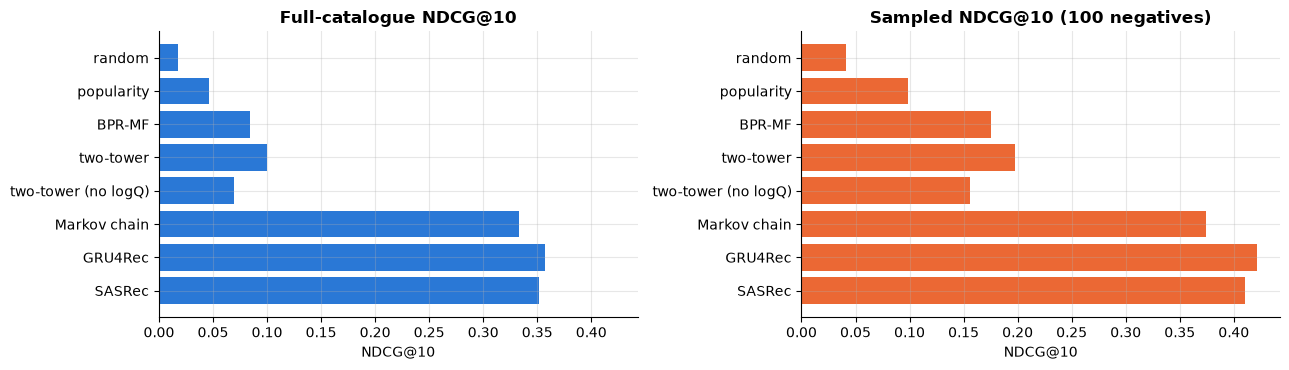

model order by full NDCG@10   : ['GRU4Rec', 'SASRec', 'Markov chain', 'two-tower', 'BPR-MF', 'two-tower (no logQ)', 'popularity', 'random']
model order by sampled NDCG@10: ['GRU4Rec', 'SASRec', 'Markov chain', 'two-tower', 'BPR-MF', 'two-tower (no logQ)', 'popularity', 'random']


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)        # same x-axis, so the inflation is visible
order = res_df.index.tolist()
ax[0].barh(order, res_df["NDCG@10"], color=PALETTE[0]); ax[0].set_title("Full-catalogue NDCG@10"); ax[0].invert_yaxis()
ax[1].barh(order, res_df["sampled NDCG@10"], color=PALETTE[1]); ax[1].set_title("Sampled NDCG@10 (100 negatives)"); ax[1].invert_yaxis()
for a in ax:
    a.set_xlabel("NDCG@10")
plt.tight_layout(); plt.show()
print("model order by full NDCG@10   :", list(res_df["NDCG@10"].sort_values(ascending=False).index))
print("model order by sampled NDCG@10:", list(res_df["sampled NDCG@10"].sort_values(ascending=False).index))

**What just happened?** Read the results table above.
- The **Markov chain** is a strong, almost free baseline: it captures the "next episode" habit (35% of all moves). Real sequential data (sessions, playlists, series) is often like this, which is why you should always include simple baselines.
- **GRU4Rec** and **SASRec** also capture the **interleaving** habit (continue the show from two items ago), which a first-order Markov chain cannot see, plus some genre taste, so they come out clearly on top of the full-catalogue metrics. They are about equally good here; SASRec usually pulls ahead on longer sequences and bigger data.
- The **taste-only** models (BPR, two-tower) cannot exploit order, so they trail far behind on next-item prediction even though they learn genre taste well.
- Compare the two bar charts: sampled metrics inflate every model (random more than doubles its NDCG@10). Here the order of models happens to survive, but because a sampled metric is a different function of the rank distribution, it can reorder models whose rank distributions cross (Krichene & Rendle, 2020). Recent work therefore evaluates against the full catalogue, or corrects the sampled metrics.

**Complexity per user request:** Markov O(n_items) lookup; GRU O(T·d²) to read the sequence plus O(d·n_items) for the softmax; SASRec O(T²·d + T·d²) per layer, but parallel over positions during training (GRU is sequential over T). For very large catalogues, the final softmax is replaced by ANN retrieval over item embeddings, just like the two-tower model.

## 5. Retrieval → ranking → re-ranking

> 💬 **In plain English:** a cheap first pass picks candidates, a smarter model sorts them, and a final pass makes the list varied and balanced.

Production systems split the work into stages, each with more compute per item and fewer items:

```
 all items (10^6–10^9)
   │  candidate generation: two-tower ANN, co-visitation / Markov, popularity, ...   (cheap, high recall)
   ▼
 ~10^2–10^3 candidates
   │  ranking: a richer model with cross features (GBDT or deep ranker)               (expensive, precise)
   ▼
 ~10^1–10^2 ranked items
   │  re-ranking: business rules, diversity, calibration, freshness, fairness
   ▼
 the list shown to the user
```

Here: **retrieval** = the union of the two-tower top-30 and the Markov top-20; **ranking** = a gradient-boosted classifier trained on the **validation** step with features from all our models; then we **re-rank** for diversity and calibration and evaluate on the **test** step.

In [11]:
def candidates_and_features(split):
    S_tt_, S_mk = S_tt.copy(), markov_scores(split)
    S_g, S_s = seq_scores(gru, split), seq_scores(sas, split)
    y = target(split)
    rows, labels, groups = [], [], []
    for u in range(n_users):
        seen = history(u, split)
        a = S_tt_[u].copy(); a[seen] = -np.inf
        b = S_mk[u].copy(); b[seen] = -np.inf
        cand = np.unique(np.r_[np.argsort(-a)[:30], np.argsort(-b)[:20]])          # multi-source retrieval
        last = seen[-1]
        feats = np.c_[S_tt_[u, cand], S_bpr[u, cand], S_mk[u, cand], S_g[u, cand], S_s[u, cand],
                      np.log1p(pop_count[cand]), item_genre[cand] == item_genre[last],
                      (item_genre[cand] == item_genre[last]) & (item_pos[cand] == item_pos[last] + 1)]
        rows.append(feats); labels.append(cand == y[u]); groups.append(np.c_[np.full(len(cand), u), cand])
    return np.vstack(rows), np.concatenate(labels), np.vstack(groups)

Xv_, yv_, gv_ = candidates_and_features("val")
Xt_, yt_, gt_ = candidates_and_features("test")
print(f"retrieval recall (target among ~{len(gt_) / n_users:.0f} candidates): val {yv_.sum() / n_users:.3f}, test {yt_.sum() / n_users:.3f}")
ranker = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0).fit(Xv_, yv_)
p_test = ranker.predict_proba(Xt_)[:, 1]

S_rank = np.full((n_users, n_items), -1e9)                  # items outside the candidate set rank last
S_rank[gt_[:, 0], gt_[:, 1]] = p_test
results["pipeline: retrieve + GBDT rank"] = evaluate(S_rank)
pd.DataFrame(results).T[["Recall@10", "NDCG@10", "MRR"]].round(3)

retrieval recall (target among ~45 candidates): val 0.644, test 0.636


,Recall@10,NDCG@10,MRR
random,0.038,0.017,0.023
popularity,0.092,0.046,0.048
BPR-MF,0.167,0.084,0.079
two-tower,0.191,0.099,0.091
two-tower (no logQ),0.154,0.069,0.063
Markov chain,0.362,0.333,0.336
GRU4Rec,0.425,0.358,0.348
SASRec,0.423,0.352,0.342
pipeline: retrieve + GBDT rank,0.469,0.377,0.360


**Re-ranking for diversity and calibration.**
- **MMR (maximal marginal relevance,** Carbonell & Goldstein, 1998) builds the list greedily, each time adding the item that maximises `λ·relevance − (1 − λ)·max similarity to items already chosen`. We use the two-tower item embeddings for similarity.
- **Calibration** (Steck, 2018): the genre mix of the list should match the genre mix of the user's history. We measure the KL divergence `KL(p_history ‖ q_list)` (with a little smoothing), and a calibrated re-ranker greedily maximises `(1 − λ)·relevance − λ·KL`.

In [12]:
def genre_dist(items, alpha=0.01):
    p = np.bincount(item_genre[items], minlength=G).astype(float) + alpha
    return p / p.sum()
def kl(p, q):
    return float((p * np.log(p / q)).sum())

def rerank(u, cand, rel, method, lam, k=10):
    chosen = []
    p_hist = genre_dist(history(u, "test"))
    for _ in range(k):
        best, best_val = None, -np.inf
        for c in range(len(cand)):
            if c in chosen:
                continue
            if method == "mmr":
                sim = max((V_tt[cand[c]] @ V_tt[cand[j]] for j in chosen), default=0.0)
                val = lam * rel[c] - (1 - lam) * sim
            else:                                            # calibration
                val = (1 - lam) * rel[c] - lam * kl(p_hist, genre_dist(cand[chosen + [c]]))
            if val > best_val:
                best, best_val = c, val
        chosen.append(best)
    return cand[chosen]

def list_metrics(lists):
    hits, ndcg, n_gen, mis = [], [], [], []
    for u, L in lists.items():
        pos = np.flatnonzero(L == test_target[u])
        hits.append(len(pos) > 0); ndcg.append(1 / np.log2(pos[0] + 2) if len(pos) else 0)
        n_gen.append(len(np.unique(item_genre[L]))); mis.append(kl(genre_dist(history(u, "test")), genre_dist(L)))
    return {"Recall@10": np.mean(hits), "NDCG@10": np.mean(ndcg), "genres in top-10": np.mean(n_gen),
            "miscalibration KL": np.mean(mis)}

eval_users = np.arange(300)                                 # a subset keeps the greedy loops quick
per_user = {}
for u in eval_users:
    m_ = gt_[:, 0] == u
    per_user[u] = (gt_[m_, 1], p_test[m_] / p_test[m_].max())  # relevance rescaled to [0, 1] per user
rows = {"ranker only": list_metrics({u: c[np.argsort(-r)[:10]] for u, (c, r) in per_user.items()})}
for lam in (0.9, 0.7):
    rows[f"MMR λ={lam}"] = list_metrics({u: rerank(u, c, r, "mmr", lam) for u, (c, r) in per_user.items()})
for lam in (0.3, 0.7):
    rows[f"calibrated λ={lam}"] = list_metrics({u: rerank(u, c, r, "cal", lam) for u, (c, r) in per_user.items()})
pd.DataFrame(rows).T.round(3)

,Recall@10,NDCG@10,genres in top-10,miscalibration KL
ranker only,0.443,0.346,4.470,1.010
MMR λ=0.9,0.407,0.332,6.547,0.588
MMR λ=0.7,0.367,0.312,7.983,0.632
calibrated λ=0.3,0.433,0.329,5.587,0.172
calibrated λ=0.7,0.417,0.274,5.737,0.118


**What just happened?** Multi-source retrieval keeps the right item among roughly 45 candidates for about two thirds of users (the rest can never be recovered by later stages, which is why retrieval recall matters so much), and the GBDT ranker, which combines all model scores with simple cross features ("same genre as the last item", "is the next episode"), matches or beats the best single model. Re-ranking then trades accuracy for other goals: **MMR** increases the number of genres in the top-10 at some cost in NDCG, and **calibration** brings the list's genre mix closer to the user's history (lower KL). The right trade-off is a product decision, usually settled with online A/B tests.

> ⚠️ **Common mistake:** training the ranker on the same interactions the retrieval models were trained on. The scores of training items are over-confident, so the ranker learns the wrong weights. Here the ranker is trained on the held-out validation step and evaluated on the test step.

## 6. Cold start with content features

> 💬 **In plain English:** a brand-new item has no history, so describe it by its features instead.

**Item cold start:** a new item has no interactions, so its ID embedding is untrained noise. A pure ID model (BPR, or the ID part of the two-tower) cannot rank it. The **content path** of our hybrid item tower maps metadata to the same embedding space, so a brand-new item gets a sensible vector on day one.

We launch **40 new items** (4 per genre, with hidden qualities) that appear in no training data, compute their content features, and ask each model to rank them for every user. Since we simulated the users, we know the **true utility** `θ_u[genre] · popularity weight` of each new item for each user and use it as graded relevance for NDCG@10.

In [13]:
r_cold = np.random.default_rng(77)
new_genre = np.repeat(np.arange(G), 4)
new_quality = r_cold.normal(0, 1, len(new_genre))
new_feat = make_content(new_genre, new_quality, r_cold)
true_util = theta[:, new_genre] * np.exp(0.8 * new_quality)[None, :]     # (n_users, 40): what users would like

def ndcg_graded(S, rel, k=10):
    """NDCG@k with graded relevance, averaged over users."""
    out = []
    for s, r_ in zip(S, rel):
        top = np.argsort(-s)[:k]; ideal = np.sort(r_)[::-1][:k]
        disc = 1 / np.log2(np.arange(2, k + 2))
        out.append((r_[top] * disc).sum() / (ideal * disc).sum())
    return float(np.mean(out))

with torch.no_grad():
    V_new = tt.item_vec(torch.zeros(len(new_genre), dtype=torch.long), torch.tensor(new_feat), use_id=False).numpy()
S_cold_content = U_tt @ V_new.T                                         # content-only item vectors
S_cold_random = np.random.default_rng(0).random(true_util.shape)
S_cold_id = U_tt @ F.normalize(torch.randn(len(new_genre), 32) * 0.05, dim=-1).numpy().T   # untrained IDs
S_cold_qual = np.tile(new_feat[:, G], (n_users, 1))                    # "popular-looking": noisy quality only
zscore = lambda S: (S - S.mean(1, keepdims=True)) / S.std(1, keepdims=True)
S_cold_blend = zscore(S_cold_content) + zscore(S_cold_qual)            # personal taste + global quality prior
cold = pd.Series({"random": ndcg_graded(S_cold_random, true_util),
                  "ID-only model (untrained IDs)": ndcg_graded(S_cold_id, true_util),
                  "quality feature only (same list for everyone)": ndcg_graded(S_cold_qual, true_util),
                  "two-tower content path (personalised)": ndcg_graded(S_cold_content, true_util),
                  "content path + quality prior (blend)": ndcg_graded(S_cold_blend, true_util)},
                 name="graded NDCG@10 on 40 new items")
cold.round(3)

random                                           0.224
ID-only model (untrained IDs)                    0.240
quality feature only (same list for everyone)    0.584
two-tower content path (personalised)            0.589
content path + quality prior (blend)             0.672
Name: graded NDCG@10 on 40 new items, dtype: float64

**What just happened?** An ID-only model is no better than random on new items, because untrained ID embeddings carry no information. The (noisy) quality feature alone is already a strong baseline here, since good items appeal to everyone, but it gives every user the same list. The content path of the hybrid two-tower model, trained with ID dropout, personalises: it maps "genre-looking" features to the region of embedding space where fans of that genre live, and scores about as well on its own. **Blending** the personalised score with the global quality prior is clearly best: personal taste and item quality are complementary signals.

**Other cold-start tools:** for **new users**, use onboarding questions, context (device, location, time), or session-based sequential models that need no user ID; for **new items**, also add exploration (bandits) so they collect feedback quickly.

## 7. Offline vs online evaluation: inverse propensity scoring

> 💬 **In plain English:** estimate how a new recommender would perform using logs collected by the old one, correcting for what the old one chose to show.

Offline metrics use logs produced by the **current** recommender (the *logging policy* π₀): we only observe feedback on items it chose to show. To estimate how a **new** policy π would perform without an A/B test, we need **off-policy evaluation** (see [bandits](../../11_Reinforcement_Learning/07_multi_armed_bandits.ipynb)).

**Setting:** for each user (context x), π₀ shows one item a with known probability π₀(a | x) and we record a click r ∈ {0, 1}. The value of π is `V(π) = E_x[ E_{a~π(·|x)} r(x, a) ]`.

| Estimator | Formula | Property |
|---|---|---|
| naive "replay" | average r over logged events where π would have chosen the same a | **biased** when π₀ is not uniform |
| **IPS** | `(1/n) Σ 1[π(xᵢ) = aᵢ] · rᵢ / π₀(aᵢ \| xᵢ)` | **unbiased** if π₀(a \| x) > 0 wherever π acts; high variance |
| **SNIPS** (self-normalised) | IPS divided by `(1/n) Σ 1[π(xᵢ) = aᵢ] / π₀(aᵢ \| xᵢ)` | small bias, much lower variance |

Because we simulated the users, we can compute the **true** V(π) and check each estimator.

In [14]:
def click_prob(users, items):
    """True click probability (known only because we wrote the simulator)."""
    return 0.02 + 0.6 * theta[users, item_genre[items]] / (1 + np.exp(-quality[items]))

# Logging policy pi0: softmax over log-popularity (shows popular items much more often)
logits0 = 1.5 * np.log(pop_count + 1)
pi0 = np.exp(logits0 - logits0.max()); pi0 /= pi0.sum()
# Target policy pi: find the genre the two-tower model scores highest for the user, show one item from it
genre_score = np.stack([S_tt[:, item_genre == g_].mean(1) for g_ in range(G)], axis=1)
fav_genre = genre_score.argmax(1)
r_pol = np.random.default_rng(8)
pi_item = np.array([r_pol.choice(np.flatnonzero(item_genre == fav_genre[u])) for u in range(n_users)])
V_true = click_prob(np.arange(n_users), pi_item).mean()
V_logging = (click_prob(np.repeat(np.arange(n_users), n_items), np.tile(np.arange(n_items), n_users)) * np.tile(pi0, n_users)).sum() / n_users

def simulate_log(n_events, seed):
    r = np.random.default_rng(seed)
    users = r.integers(0, n_users, n_events)
    items = r.choice(n_items, n_events, p=pi0)
    clicks = r.random(n_events) < click_prob(users, items)
    return users, items, clicks

est = {"naive replay": [], "IPS": [], "SNIPS": []}
n_logs = 300
for seed in range(n_logs):
    users, items, clicks = simulate_log(50000, seed)
    match = items == pi_item[users]
    w = match / pi0[items]
    est["naive replay"].append(clicks[match].mean() if match.any() else np.nan)
    est["IPS"].append((w * clicks).mean())
    est["SNIPS"].append((w * clicks).sum() / w.sum())
ope = pd.DataFrame({k: {"mean estimate": np.nanmean(v), "bias": np.nanmean(v) - V_true,
                        "std. error of the bias": np.nanstd(v) / np.sqrt(n_logs), "std over logs": np.nanstd(v)}
                    for k, v in est.items()}).T
print(f"true value of the new policy V(pi) = {V_true:.4f};  value of the logging policy = {V_logging:.4f}")
ope.round(4)

true value of the new policy V(pi) = 0.1282;  value of the logging policy = 0.0568


,mean estimate,bias,std. error of the bias,std over logs
naive replay,0.1517,0.0236,0.0017,0.0286
IPS,0.1271,-0.0011,0.0022,0.0380
SNIPS,0.1255,-0.0026,0.0020,0.0355


**What just happened?** The logs come from a popularity-heavy policy (its overall click rate is far below the new policy's), so the new policy's choices were rarely shown. The naive replay average is clearly **biased** upwards: the users for whom π₀ happened to show π's item are mostly users whose π-item is popular, and popular items are also better, so those users click more. **IPS** is within half a standard error of the truth over 300 simulated logs (it is unbiased), and **SNIPS** within about 1.3 standard errors (it has a small bias that vanishes as the log grows), but each individual estimate is noisy (see the last column); SNIPS has the smaller spread. If π₀ never shows an item (π₀(a|x) = 0), no estimator can evaluate a policy that picks it: logging policies need **exploration**.

> 🎓 **Exam / interview tip:** "Offline metrics improved but the A/B test was flat. Why?" Typical answers: offline logs are biased towards what the old model showed (exposure bias), sampled metrics, leakage in the split, a mismatch between the offline metric and the business metric, and feedback loops. Off-policy estimators (IPS, SNIPS, doubly robust) and small online tests close the gap.

## 8. A latency and size budget for production

> 💬 **In plain English:** every stage must be fast enough and small enough for millions of requests.

In [15]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

def time_per_request(fn, reps=200):
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1000

Xi, lasti = make_inference_tensors("test")
u0 = 0
with torch.no_grad():
    lat = {
        "popularity": (0, time_per_request(lambda: np.argpartition(-pop_count, 10)[:10])),
        "BPR-MF (score all items)": (n_params(bpr), time_per_request(lambda: np.argpartition(-(S_bpr[u0]), 10)[:10])),
        "two-tower + exact dot products": (n_params(tt), time_per_request(lambda: np.argpartition(-(V_tt @ U_tt[u0]), 10)[:10])),
        "two-tower + IVF (n_probe=2)": (n_params(tt), time_per_request(lambda: ivf_search(U_tt[u0], C_ivf, lists, V_tt, n_probe=2))),
        "Markov chain (row lookup)": (T_counts.size, time_per_request(lambda: np.argpartition(-T_counts[seqs[u0][-1]], 10)[:10])),
        "GRU4Rec (forward pass, batch of 1)": (n_params(gru), time_per_request(lambda: gru(Xi[u0:u0 + 1]), reps=50)),
        "SASRec (forward pass, batch of 1)": (n_params(sas), time_per_request(lambda: sas(Xi[u0:u0 + 1]), reps=50)),
    }
budget = pd.DataFrame({k: {"parameters": v[0], "size (MB, float32)": v[0] * 4 / 1e6, "latency per request (ms)": v[1]}
                       for k, v in lat.items()}).T
budget.round(3)

,parameters,"size (MB, float32)",latency per request (ms)
popularity,0.0,0.000,0.016
BPR-MF (score all items),41900.0,0.168,0.024
two-tower + exact dot products,78784.0,0.315,0.027
two-tower + IVF (n_probe=2),78784.0,0.315,0.037
Markov chain (row lookup),90000.0,0.360,0.007
"GRU4Rec (forward pass, batch of 1)",63724.0,0.255,2.183
"SASRec (forward pass, batch of 1)",54384.0,0.218,1.241


**What just happened?** On this toy catalogue every model answers in well under a millisecond to a few milliseconds per request on a CPU (your numbers will vary with the machine and its load). The point is how each one **scales**: scoring all items grows linearly with the catalogue, ANN grows roughly with the number of probed items, Markov tables grow with n_items² unless stored sparsely, and sequence models pay for a forward pass over the history on every request.

**A typical production budget** (orders of magnitude often quoted for large consumer apps; real figures vary by company):

| Stage | Items in → out | Latency budget | Typical model | Size concerns |
|---|---|---|---|---|
| Candidate generation | 10⁶–10⁹ → 10³ | ~10–20 ms | two-tower + ANN index, co-visitation tables, popular/fresh lists | embedding table: n_items × d × 4 bytes (100M × 64 × 4 B = 25.6 GB) → quantise, shard |
| Ranking | 10³ → 10² | ~20–50 ms | GBDT or deep ranker (DLRM, DCN, transformers over user history) with cross features | feature-store lookups often dominate latency |
| Re-ranking | 10² → 10¹ | ~5–10 ms | rules, MMR, calibration, business constraints | |
| End to end (p99) | | ~100–200 ms | | caching, batching, async feature fetch |

> ⚠️ **Common mistake:** reporting only average latency. Users feel the **tail** (p95/p99), and a single slow feature lookup can blow the budget.

## 9. 🔗 How this connects to modern AI

- **Generative recommenders and LLMs**: sequential recommenders are next-token predictors over item IDs. Recent systems go further, with "semantic IDs" (items tokenised by quantising their embeddings, e.g. RQ-VAE codes) and transformer models that generate the next item's ID, the same recipe as an LLM ([`05_Deep_Learning/05_transformers_architecture`](../../05_Deep_Learning/05_transformers_architecture.ipynb)).
- **Retrieval for RAG** uses exactly the two-tower + ANN pattern: a query encoder, a document encoder, in-batch negatives with temperature (the contrastive loss of DPR/E5-style embedding models), an ANN index, then a cross-encoder **re-ranker**, the same retrieve → rank → re-rank pipeline ([`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)).
- **LLMs as rankers or explainers**: LLMs are used to re-rank candidates, generate item descriptions for cold-start content features, and explain recommendations.
- **Bandits and RL**: exploration for new items, and off-policy evaluation (IPS, doubly robust) are used for recommenders, ads and also for evaluating LLM policies from logged feedback ([`11_Reinforcement_Learning/07_multi_armed_bandits`](../../11_Reinforcement_Learning/07_multi_armed_bandits.ipynb)).

## 10. Recap

- Evaluate sequential recommenders with a **time-respecting split** (leave-last-out) and **full-catalogue** Recall@k / NDCG@k / MRR; sampled metrics inflate scores and can reorder models. Track **coverage** and **popularity bias** too.
- **BPR** learns from implicit feedback with a pairwise ranking loss.
- **Two-tower** models (in-batch softmax, temperature, logQ correction) give indexable embeddings; **IVF/ANN** search trades a little recall for big speed-ups.
- **Sequence models** (Markov → GRU4Rec → SASRec) exploit order; a Markov chain is a strong baseline when sequences are very regular.
- Production uses **retrieval → ranking → re-ranking**; train rankers on held-out interactions; re-rank for **diversity (MMR)** and **calibration**.
- **Cold start**: content features through a hybrid tower trained with ID dropout.
- **Off-policy evaluation**: naive replay is biased; **IPS** is unbiased but noisy; **SNIPS** reduces variance. Logging policies must explore.
- Budget for **latency and memory** per stage; watch p99, not just the mean.

## Practice problems

**1. (Easy, conceptual)** The target item is ranked 3rd out of 280 unseen items. What are Recall@10, NDCG@10 and the reciprocal rank? What if it is ranked 25th?
<details><summary>Show solution</summary>

Rank 3: Recall@10 = 1, NDCG@10 = 1/log₂(4) = 0.5, RR = 1/3. Rank 25: Recall@10 = 0, NDCG@10 = 0, RR = 0.04.
```python
import numpy as np
def metrics_from_rank(r, k=10):
    """r: 1-based rank of the single relevant item."""
    return {"recall@k": float(r <= k), "ndcg@k": 1 / np.log2(r + 1) if r <= k else 0.0, "rr": 1 / r}
```

</details>

**2. (Easy, conceptual)** Why does evaluating against 100 sampled negatives inflate metrics, and when can it change which model looks best?
<details><summary>Show solution</summary>

With 100 negatives, a target only needs to beat 100 random items instead of every item; random items are mostly easy (unpopular, off-taste), so almost every model ranks the target near the top. Model differences that show up in the hard part of the ranking (beating the strong competitors among the full catalogue) disappear. Because sampled Recall@k is a different function of the full rank distribution, it can even reverse the order of two models whose rank distributions cross (Krichene & Rendle, 2020).

</details>

**3. (Medium, conceptual)** In-batch negatives are sampled roughly in proportion to item popularity. Explain the logQ correction and what goes wrong without it.
<details><summary>Show solution</summary>

The in-batch softmax approximates the full softmax with a sample of negatives drawn with probability Q(j) ∝ popularity. The sampled-softmax estimator is unbiased only if each logit is corrected by subtracting log Q(j) (Bengio & Senécal; Yi et al., 2019 for two-tower models). Without the correction, popular items appear as negatives far more often and are pushed down too much; the learned scores reflect "popularity-adjusted" preference in a way that depends on the batch size and sampling distribution, rather than the true softmax.

</details>

**4. (Medium, coding)** Implement MMR re-ranking given a relevance vector and an item-item similarity matrix, and check that it replaces a near-duplicate with a different item.
<details><summary>Show solution</summary>

```python
import numpy as np
def mmr(rel, sim, k, lam=0.7):
    """rel: (n,) relevance; sim: (n, n) item-item similarity. Returns indices of the chosen list."""
    chosen = []
    while len(chosen) < k:
        best, best_val = None, -np.inf
        for c in range(len(rel)):
            if c in chosen:
                continue
            penalty = max((sim[c, j] for j in chosen), default=0.0)
            val = lam * rel[c] - (1 - lam) * penalty
            if val > best_val:
                best, best_val = c, val
        chosen.append(best)
    return chosen
```

</details>

**5. (Medium, coding)** Implement IPS and SNIPS for a deterministic new policy, and check them on a 5-armed bandit log where the truth is known.
<details><summary>Show solution</summary>

```python
import numpy as np
def ips_snips(chosen_by_new, logged, rewards, propensities):
    """Off-policy estimates for a deterministic new policy from logged bandit data."""
    w = (chosen_by_new == logged) / propensities
    ips = np.mean(w * rewards)
    snips = np.sum(w * rewards) / np.sum(w) if w.sum() > 0 else np.nan
    return ips, snips
```
With 200 000 logged events, both estimates for "always show arm 2" are within 0.02 of the true click rate 0.3, although the logging policy showed arm 2 only 10% of the time.

</details>

**6. (Medium, conceptual)** Your GRU4Rec beats the Markov chain offline by 2% NDCG, but costs 30× more to serve. What would you check before shipping it?
<details><summary>Show solution</summary>

Whether the gain is statistically significant (bootstrap CIs over users) and holds on segments that matter (new users, long sessions, the long tail); whether it survives an online A/B test on business metrics; whether a cheaper hybrid (Markov + a taste model in a GBDT ranker) captures most of the gain; latency at p99 with realistic batching; and the cost of retraining and monitoring. A small offline gain for a large serving cost often does not pay off.

</details>

**7. (Hard, coding project)** Add **BERT4Rec**-style training to the SASRec model: instead of next-item prediction, randomly mask 20% of the items in each sequence (a `[MASK]` token id) and predict them with bidirectional attention; at inference append `[MASK]` at the end. Compare with SASRec on this data.
<details><summary>Show solution</summary>

Sketch: add one extra embedding row for `[MASK]`; build inputs by replacing a random 20% of real positions with the mask id and set targets only at those positions (−100 elsewhere); remove the causal mask (use a key-padding mask instead, and avoid fully masked rows); at test time input `history + [MASK]` and read the logits at the mask position. Results on short, regular sequences like ours are usually similar to SASRec; Petrov & Macdonald (2022) found that BERT4Rec's reported advantages are sensitive to training length and implementation details, which is a good lesson in careful baselines.

</details>

**8. (Hard, design)** Sketch a recommender for a news app with 1 million articles per day, 50 million users and a 150 ms budget.
<details><summary>Show solution</summary>

Candidate generation: a two-tower model (user history encoder; article tower from **content** since every article is cold) with an ANN index rebuilt continuously, plus fresh/trending and follow-based sources. Ranking: a deep ranker or GBDT with recency, user-topic affinity, popularity velocity and context; features from a low-latency feature store. Re-ranking: diversity (MMR over topics), freshness boosts, editorial and safety rules, de-duplication of near-identical stories. Exploration (bandit) for new articles; off-policy evaluation plus A/B tests; monitoring of coverage, popularity bias and latency p99.

</details>

## Further reading
- C. C. Aggarwal, *Recommender Systems: The Textbook* (2016), ch. 1–3 and 13.
- S. Rendle et al. (2009), "BPR: Bayesian Personalized Ranking from Implicit Feedback"; B. Hidasi et al. (2016), "Session-based Recommendations with Recurrent Neural Networks"; W.-C. Kang & J. McAuley (2018), "Self-Attentive Sequential Recommendation".
- X. Yi et al. (2019), "Sampling-Bias-Corrected Neural Modeling for Large Corpus Item Recommendations"; P. Covington, J. Adams & E. Sargin (2016), "Deep Neural Networks for YouTube Recommendations".
- W. Krichene & S. Rendle (2020), "On Sampled Metrics for Item Recommendation"; H. Steck (2018), "Calibrated Recommendations".
- A. Swaminathan & T. Joachims (2015), "The Self-Normalized Estimator for Counterfactual Learning".
- Free: the Google Developers "Recommendation Systems" course; the Microsoft "Recommenders" GitHub repository (best-practice notebooks).

## Next notebook
⬅️ Previous: [Clustering and manifold learning in depth](../02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb) · ➡️ Next: [AutoML from scratch](../../15_MLOps/08_automl/02_automl_from_scratch.ipynb)